# Fase 5B — Estudo de sementes do BERTimbau

### O que este notebook faz

Treina o BERTimbau com cinco sementes diferentes e mede, em cada modelo, a taxa de acerto no teste e a detecção sobre as notícias sintéticas nas duas formas de texto. Responde se a diferença entre execuções observada nas Fases 5 e 7 é propriedade do modelo ou acaso de uma rodada. Não altera o modelo de referência: os modelos deste estudo são descartados depois de avaliados, e só os números ficam.

### Entradas

- `dados/corpus_preparado.csv`
- `dados/sinteticas_processadas.csv`

### Saídas de dados

- `dados/estudo_sementes.csv`
- `dados/estudo_sementes_resumo.csv`

### Figuras geradas

- `figuras/fig_sementes.png` — taxa de acerto, detecção e especificidade de cada semente, com a média

## 1. Ambiente

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

BASE    = Path('/content/drive/MyDrive/TCC')
DADOS   = BASE / 'dados'
FIGURAS = BASE / 'figuras'
MODELOS = BASE / 'modelos'
for pasta in (DADOS, FIGURAS, MODELOS):
    pasta.mkdir(parents=True, exist_ok=True)

print('projeto :', BASE)
print('dados   :', DADOS)
print('figuras :', FIGURAS)
print('modelos :', MODELOS)


Mounted at /content/drive
projeto : /content/drive/MyDrive/TCC
dados   : /content/drive/MyDrive/TCC/dados
figuras : /content/drive/MyDrive/TCC/figuras
modelos : /content/drive/MyDrive/TCC/modelos


## 2. Padrão visual das figuras

Mesmo módulo das demais fases: a célula grava `estilo_sbc.py` e a seguinte o importa. O cabeçalho do módulo justifica cada decisão visual em relação ao template da SBC.

In [2]:
%%writefile /content/estilo_sbc.py
# -*- coding: utf-8 -*-
import io
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, MaxNLocator
from PIL import Image

AZUL    = '#1B4F72'
LARANJA = '#D55E00'
AMBAR   = '#E8B04B'
VERDE   = '#117733'
TEXTO   = '#1A1A1A'
SUAVE   = '#5F6B7A'
GRADE   = '#E4E7EA'
NEUTRO  = '#C3C9D0'

PALETA  = [AZUL, LARANJA, AMBAR, VERDE]

AZUL_TEXTO    = AZUL
LARANJA_TEXTO = '#A64A00'
AMBAR_TEXTO   = '#8A6410'
VERDE_TEXTO   = '#0E5C28'

_LEGIVEL = {AZUL: AZUL_TEXTO, LARANJA: LARANJA_TEXTO,
            AMBAR: AMBAR_TEXTO, VERDE: VERDE_TEXTO}

T_PEQUENO  = 8.0
T_CORPO    = 9.0
T_ROTULO   = 9.5
T_TITULO   = 10.5
T_DESTAQUE = 13.0


def legivel(cor):
    return _LEGIVEL.get(cor, cor)


CORES_MODELO = {
    'Regressao Logistica': AZUL,
    'Regressão Logística': AZUL,
    'Random Forest': LARANJA,
    'BERTimbau': AMBAR,
}
CORES_CLASSE = {'Verdadeira': AZUL, 'Falsa': LARANJA}

MAPA_FRIO = LinearSegmentedColormap.from_list('sbc_frio', ['#F1F4F5', AZUL])
MAPA_DIV  = LinearSegmentedColormap.from_list('sbc_div', [AZUL, '#FFFFFF', LARANJA])

CM = 1 / 2.54
LARGURA = 15 * CM
LARGURA_MEIA = 7.2 * CM

_instaladas = {f.name for f in mpl.font_manager.fontManager.ttflist}
FAMILIA = next((f for f in ('Inter', 'Source Sans 3', 'Lato', 'Open Sans',
                            'Liberation Sans', 'DejaVu Sans')
                if f in _instaladas), 'sans-serif')

mpl.rcParams.update({
    'figure.dpi': 110,
    'savefig.dpi': 400,
    'savefig.bbox': 'tight',
    'savefig.facecolor': 'white',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',

    'font.family': FAMILIA,
    'font.size': T_CORPO,
    'axes.titlesize': T_TITULO,
    'axes.titleweight': 'bold',
    'axes.titlepad': 12,
    'axes.labelsize': T_CORPO,
    'axes.labelcolor': TEXTO,
    'axes.labelpad': 10,
    'xtick.labelsize': T_CORPO,
    'ytick.labelsize': T_CORPO,
    'legend.fontsize': T_CORPO,

    'text.color': TEXTO,
    'axes.edgecolor': '#B9BDC2',
    'axes.linewidth': 0.8,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.spines.left': False,

    'xtick.color': SUAVE,
    'ytick.color': SUAVE,
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'xtick.major.size': 0,
    'ytick.major.size': 0,
    'xtick.major.pad': 5,
    'ytick.major.pad': 5,

    'grid.color': GRADE,
    'grid.linewidth': 0.8,
    'axes.grid': False,

    'legend.frameon': False,
    'legend.handlelength': 1.2,
    'legend.handleheight': 1.2,
    'legend.columnspacing': 2.2,
    'legend.borderpad': 0.1,
    'legend.labelspacing': 0.6,

    'axes.prop_cycle': mpl.cycler(color=PALETA),
    'lines.linewidth': 2.0,
    'lines.markersize': 6,
    'patch.linewidth': 0,
})

_destino = Path('.')


def destino(pasta):
    global _destino
    _destino = Path(pasta)
    _destino.mkdir(parents=True, exist_ok=True)
    return _destino


def salvar(fig, nome, largura_cm=15.0, dpi=400):
    caminho = _destino / (nome + '.png')
    if largura_cm is None:
        fig.savefig(caminho, dpi=dpi, bbox_inches='tight', facecolor='white')
        print('[figura]', caminho.name, '(sem normalizacao)')
        return caminho

    alvo = int(round(largura_cm / 2.54 * dpi))
    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=dpi, bbox_inches='tight',
                facecolor='white')
    buf.seek(0)
    im = Image.open(buf).convert('RGB')
    nota = ''
    if im.width > alvo:
        fator = alvo / im.width
        im = im.resize((alvo, max(1, int(round(im.height * fator)))),
                       Image.LANCZOS)
        nota = '  (reduzida {:.1%})'.format(1 - fator)
    elif im.width < alvo:
        tela = Image.new('RGB', (alvo, im.height), 'white')
        tela.paste(im, ((alvo - im.width) // 2, 0))
        im = tela
        nota = '  (margem branca completada)'
    im.save(caminho, dpi=(dpi, dpi))
    print('[figura] {:<30} {:.1f} x {:.1f} cm{}'
          .format(caminho.name, largura_cm, im.height / dpi * 2.54, nota))
    return caminho

def br(texto):
    return str(texto).replace(',', '\u0000').replace('.', ',').replace('\u0000', '.')


def pct(valor, dec=1):
    return br(('{:.' + str(dec) + 'f}').format(100 * valor)) + '%'


def mil(valor, dec=0):
    return br(('{:,.' + str(dec) + 'f}').format(valor))


def grade_y(ax, atras=True):
    ax.grid(axis='y', color=GRADE, linewidth=0.8)
    ax.grid(axis='x', visible=False)
    ax.set_axisbelow(atras)
    return ax


def grade_x(ax, atras=True):
    ax.grid(axis='x', color=GRADE, linewidth=0.8)
    ax.grid(axis='y', visible=False)
    ax.set_axisbelow(atras)
    return ax


def sem_grade(ax):
    ax.grid(False)
    for lado in ('top', 'right', 'left', 'bottom'):
        ax.spines[lado].set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])
    return ax


def eixo_percentual(ax, eixo='y', decimais=0):
    f = FuncFormatter(lambda v, _: pct(v, decimais))
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)
    return ax


def eixo_decimal(ax, eixo='y', decimais=2):
    f = FuncFormatter(
        lambda v, _: br(('{:,.' + str(decimais) + 'f}').format(v)))
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)
    return ax


def escala_percentual(ax, maximo=1.0, folga_topo=0.20, passo=0.2, decimais=0):
    import numpy as _np
    ax.set_ylim(0, maximo * (1 + folga_topo))
    ax.set_yticks(_np.round(_np.arange(0, maximo + 1e-9, passo), 10))
    eixo_percentual(ax, 'y', decimais)
    return ax


def eixo_milhar(ax, eixo='y'):
    f = FuncFormatter(lambda v, _: mil(v))
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)
    return ax


def rotular(ax, barras, fmt='{:.1%}', dy=5, tam=T_ROTULO, peso='bold', cor=None):
    for b in barras:
        v = b.get_height()
        ax.annotate(br(fmt.format(v)),
                    xy=(b.get_x() + b.get_width() / 2, v),
                    xytext=(0, dy), textcoords='offset points',
                    ha='center', va='bottom',
                    fontsize=tam, fontweight=peso,
                    color=cor or TEXTO)
    return ax


def rotular_h(ax, barras, fmt='{:.1%}', dx=6, tam=T_ROTULO, peso='bold', cor=None):
    for b in barras:
        v = b.get_width()
        ax.annotate(br(fmt.format(v)),
                    xy=(v, b.get_y() + b.get_height() / 2),
                    xytext=(dx, 0), textcoords='offset points',
                    ha='left', va='center',
                    fontsize=tam, fontweight=peso,
                    color=cor or TEXTO)
    return ax


def encolher_para_caber(ax, textos, largura_dados, tamanho, minimo=6.5,
                        passo=0.2):
    fig = ax.figure
    fig.canvas.draw()
    renderizador = fig.canvas.get_renderer()
    base = ax.transData.transform((0, 0))[0]
    limite = ax.transData.transform((largura_dados, 0))[0] - base
    while tamanho > minimo:
        maior = max(t.get_window_extent(renderer=renderizador).width
                    for t in textos)
        if maior <= limite:
            break
        tamanho -= passo
        for t in textos:
            t.set_fontsize(tamanho)
    return tamanho


def legenda_abaixo(ax, ncols=2, afastamento=None, **kwargs):
    altura_pt = (ax.get_position().height * ax.figure.get_figheight() * 72) or 1
    if afastamento is None:
        afastamento = -(44 if ax.get_xlabel() else 24) / altura_pt
    return ax.legend(loc='upper center', ncols=ncols,
                     bbox_to_anchor=(0.5, afastamento),
                     fontsize=T_CORPO, **kwargs)


def legenda_manual(ax, itens, ncols=None, **kwargs):
    from matplotlib.patches import Patch
    marcas = [Patch(facecolor=cor, label=rotulo) for rotulo, cor in itens]
    return legenda_abaixo(ax, ncols=ncols or len(itens), handles=marcas,
                          **kwargs)


def titulo(ax, principal, apoio=None):
    linhas_apoio = apoio.count('\n') + 1 if apoio else 0
    ax.set_title(principal, loc='left',
                 pad=(25 + 12 * (linhas_apoio - 1)) if apoio else 10)
    if apoio:
        ax.annotate(apoio, xy=(0, 1), xycoords='axes fraction',
                    xytext=(0, 7), textcoords='offset points',
                    ha='left', va='bottom', fontsize=T_CORPO, color=SUAVE)
    return ax


def espacar(valores, minimo):
    import numpy as _np
    valores = _np.asarray(valores, dtype=float)
    pos = valores.copy()
    ordem = _np.argsort(valores)
    for k in range(1, len(ordem)):
        anterior, atual = ordem[k - 1], ordem[k]
        if pos[atual] - pos[anterior] < minimo:
            pos[atual] = pos[anterior] + minimo
    deslocamento = pos[ordem].mean() - valores[ordem].mean()
    return pos - deslocamento


def folga(ax, eixo='y', fator=0.14):
    if eixo == 'y':
        lo, hi = ax.get_ylim()
        ax.set_ylim(lo, hi + (hi - lo) * fator)
    else:
        lo, hi = ax.get_xlim()
        ax.set_xlim(lo, hi + (hi - lo) * fator)
    return ax


def painel_confusao(ax, matriz, titulo_painel, rotulos=('Verdadeira', 'Falsa'),
                    destaque=None):
    import numpy as np
    matriz = np.asarray(matriz, dtype=float)
    total = matriz.sum()
    ax.imshow(matriz / matriz.max(), cmap=MAPA_FRIO, vmin=0, vmax=1.15)
    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):
            v = matriz[i, j]
            claro = (v / matriz.max()) > 0.55
            ax.text(j, i - 0.10, mil(v),
                    ha='center', va='center', fontsize=T_DESTAQUE,
                    fontweight='bold',
                    color='white' if claro else TEXTO)
            ax.text(j, i + 0.22, pct(v / total, 1),
                    ha='center', va='center', fontsize=T_PEQUENO,
                    color='#E8EEF0' if claro else SUAVE)
    ax.set_xticks([0, 1], ['Predita\n' + rotulos[0], 'Predita\n' + rotulos[1]])
    ax.set_yticks([0, 1], ['Real\n' + rotulos[0], 'Real\n' + rotulos[1]])
    ax.set_title(titulo_painel, loc='center', pad=10,
                 color=legivel(destaque) if destaque else TEXTO)
    for lado in ('top', 'right', 'left', 'bottom'):
        ax.spines[lado].set_visible(False)
    ax.tick_params(length=0)
    ax.grid(False)
    return ax


def barras_pareadas(ax, categorias, series, fmt='{:.1%}', largura_grupo=0.78,
                    rotulo=True):
    import numpy as np
    x = np.arange(len(categorias))
    n = len(series)
    larg = largura_grupo / n
    for k, (nome, valores, cor) in enumerate(series):
        desloc = (k - (n - 1) / 2) * larg
        b = ax.bar(x + desloc, valores, larg * 0.92, label=nome, color=cor)
        if rotulo:
            rotular(ax, b, fmt=fmt, tam=T_PEQUENO)
    ax.set_xticks(x, categorias)
    grade_y(ax)
    return ax


print('estilo_sbc carregado  |  paleta', AZUL, LARANJA, AMBAR)


Writing /content/estilo_sbc.py


In [3]:
import shutil, sys
shutil.copy('/content/estilo_sbc.py', BASE / 'estilo_sbc.py')
sys.path.insert(0, '/content')

from estilo_sbc import *
destino(FIGURAS)

import numpy as np
import pandas as pd


estilo_sbc carregado  |  paleta #1B4F72 #D55E00 #E8B04B


## 3. Localizadores de arquivos e colunas

In [4]:
def arquivo(*nomes):
    tentados = []
    for nome in nomes:
        for pasta in (DADOS, BASE):
            alvo = pasta / nome
            tentados.append(str(alvo))
            if alvo.exists():
                return alvo
    raise FileNotFoundError(
        'Nenhum destes arquivos foi encontrado:\n  ' + '\n  '.join(tentados))


def existe(*nomes):
    try:
        return arquivo(*nomes)
    except FileNotFoundError:
        return None


def coluna(df, *candidatos, obrigatoria=True):
    mapa = {c.strip().lower(): c for c in df.columns}
    for cand in candidatos:
        if cand.strip().lower() in mapa:
            return mapa[cand.strip().lower()]
    for cand in candidatos:
        chave = cand.strip().lower()
        for norm, orig in mapa.items():
            if chave in norm:
                return orig
    if obrigatoria:
        raise KeyError('Nenhuma destas colunas existe: ' + ', '.join(candidatos)
                       + '\nDisponiveis: ' + ', '.join(map(str, df.columns)))
    return None


def csvs_do_projeto():
    achados = []
    for caminho in sorted(BASE.rglob('*.csv')):
        try:
            cabecalho = list(pd.read_csv(caminho, nrows=0).columns)
            with open(caminho, encoding='utf-8', errors='ignore') as fh:
                linhas = max(sum(1 for _ in fh) - 1, 0)
        except Exception as erro:
            cabecalho, linhas = ['<ilegível: {}>'.format(erro)], -1
        achados.append((caminho, linhas, cabecalho))
    return achados


def listar_csvs():
    achados = csvs_do_projeto()
    if not achados:
        print('nenhum CSV encontrado em', BASE)
        return
    for caminho, linhas, colunas in achados:
        print('{:<44} {:>7} linhas   {}'.format(
            str(caminho.relative_to(BASE)), linhas,
            ', '.join(map(str, colunas))[:88]))


def procurar_csv(*pistas_de_coluna, nomes=()):
    if nomes:
        alvo = existe(*nomes)
        if alvo is not None:
            return alvo
    candidatos = []
    for caminho, linhas, colunas in csvs_do_projeto():
        normalizadas = {str(c).strip().lower() for c in colunas}
        if any(any(pista in c for c in normalizadas) for pista in pistas_de_coluna):
            candidatos.append((linhas, caminho))
    if candidatos:
        candidatos.sort(reverse=True)
        escolhido = candidatos[0][1]
        print('localizado pelo conteúdo:', escolhido.relative_to(BASE))
        if len(candidatos) > 1:
            print('outros compatíveis:',
                  [str(c.relative_to(BASE)) for _, c in candidatos[1:]])
        return escolhido
    print('Nenhum CSV com coluna parecida com', pistas_de_coluna, 'foi encontrado.')
    print('Nomes procurados:', nomes or '(nenhum)')
    print('\nCSVs disponíveis em', BASE, ':')
    listar_csvs()
    raise FileNotFoundError(
        'Veja o inventário acima e renomeie o arquivo certo, ou gere-o de novo.')


def modelos_disponiveis():
    import datetime as _dt
    import json as _json
    achados = []
    for config in sorted(BASE.rglob('config.json')):
        pasta = config.parent
        if not (pasta / 'model.safetensors').exists() \
                and not (pasta / 'pytorch_model.bin').exists():
            continue
        marca = pasta / 'convencao_rotulo.json'
        convencao = None
        if marca.exists():
            try:
                convencao = _json.loads(marca.read_text(encoding='utf-8'))
            except Exception:
                convencao = {'erro': 'json ilegivel'}
        achados.append((pasta,
                        _dt.datetime.fromtimestamp(config.stat().st_mtime),
                        convencao))
    return sorted(achados, key=lambda t: t[1], reverse=True)


def listar_modelos():
    achados = modelos_disponiveis()
    if not achados:
        print('nenhum modelo encontrado em', BASE)
        return
    for pasta, quando, convencao in achados:
        print('{:<46} {}  {}'.format(
            str(pasta.relative_to(BASE)), quando.strftime('%d/%m %H:%M'),
            'rótulo 1 = ' + convencao.get('1', '?') if convencao
            else 'SEM convenção declarada'))


def achar_modelo(convencao_exigida='Falsa'):
    disponiveis = [t for t in modelos_disponiveis()
                   if 'checkpoint' not in t[0].name]
    if not disponiveis:
        return None

    corretos = [t for t in disponiveis
                if t[2] and t[2].get('1') == convencao_exigida]
    if corretos:
        return str(corretos[0][0])

    print('AVISO: nenhum modelo declara a convenção "rótulo 1 =',
          convencao_exigida, '". Usando o mais recente; confira a acurácia.')
    listar_modelos()
    return str(disponiveis[0][0])


_NLP = None


def motor_lema():
    global _NLP
    if _NLP is None:
        import spacy
        try:
            _NLP = spacy.load('pt_core_news_sm', disable=['parser', 'ner'])
        except OSError:
            import subprocess, sys
            subprocess.run([sys.executable, '-m', 'spacy', 'download',
                            'pt_core_news_sm'], check=True)
            _NLP = spacy.load('pt_core_news_sm', disable=['parser', 'ner'])
    return _NLP


def lematizar(textos, lote=32):
    nlp = motor_lema()
    return [' '.join(t.lemma_ for t in doc)
            for doc in nlp.pipe(list(textos), batch_size=lote)]


def taxa_de_lema(textos, limite=400):
    nlp = motor_lema()
    iguais = total = 0
    for doc in nlp.pipe(list(textos)[:limite], batch_size=32):
        for t in doc:
            if t.is_alpha and len(t.text) > 2:
                total += 1
                iguais += t.text.lower() == t.lemma_.lower()
    return iguais / total if total else float('nan')


## 4. Chaves de execução

A partição treino/validação/teste é a mesma da Fase 5 (semente 42); o que muda entre os modelos é só a semente de treinamento — inicialização da camada de classificação e ordem dos lotes.

Cada semente leva de 10 a 25 minutos, conforme a GPU. O resultado de cada uma é gravado assim que ela termina: se a conexão cair, rode de novo e as sementes concluídas são puladas. Os pontos de verificação ficam no disco local do Colab, não no Drive, e são apagados ao fim de cada semente.

In [5]:
SEMENTES = [1, 2, 3, 4, 5]
PARTICAO = 42

!pip install -q transformers accelerate datasets
import time, shutil, torch, datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          Trainer, TrainingArguments, DataCollatorWithPadding,
                          set_seed)
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available()
      else 'NENHUMA — ative a GPU antes de continuar')


GPU: Tesla T4


## 5. Dados

Mesma divisão da Fase 5, refeita com a mesma semente. As notícias sintéticas entram nas duas formas; se o arquivo tiver também as verdadeiras, a especificidade é medida junto.

In [6]:
df = pd.read_csv(arquivo('corpus_preparado.csv', 'corpus_base.csv')).dropna(subset=['texto'])
treino = (df['particao'] == 'treino').to_numpy()
pos_treino = np.flatnonzero(treino)
pos_tr, pos_val = train_test_split(
    pos_treino, test_size=0.10, random_state=PARTICAO,
    stratify=df.loc[treino, 'rotulo'].to_numpy())

textos, rotulos = df['texto'].to_numpy(), df['rotulo'].to_numpy()
tr_txt, tr_y = textos[pos_tr], rotulos[pos_tr]
val_txt, val_y = textos[pos_val], rotulos[pos_val]
te_txt, te_y = df.loc[~treino, 'texto'].values, df.loc[~treino, 'rotulo'].to_numpy()
print('treino {} | validação {} | teste {}'.format(
    mil(len(tr_txt)), mil(len(val_txt)), mil(len(te_txt))))

sint = pd.read_csv(arquivo('sinteticas_processadas.csv'))
if 'rotulo' not in sint.columns:
    sint['rotulo'] = 1
falsas = sint[sint['rotulo'] == 1]
verdadeiras = sint[sint['rotulo'] == 0]
print('sintéticas: {} falsas, {} verdadeiras'.format(len(falsas), len(verdadeiras)))


treino 8.568 | validação 953 | teste 2.381
sintéticas: 147 falsas, 147 verdadeiras


## 6. Treino e avaliação por semente

In [7]:
ARQ = DADOS / 'estudo_sementes.csv'
feitas = set(pd.read_csv(ARQ)['semente']) if ARQ.exists() else set()
pendentes = [s for s in SEMENTES if s not in feitas]
print('concluídas:', sorted(feitas) or 'nenhuma', '| a treinar:', pendentes or 'nenhuma')

NOME_BASE = 'neuralmind/bert-base-portuguese-cased'
tok = AutoTokenizer.from_pretrained(NOME_BASE)


def preparar(lista, alvos):
    d = datasets.Dataset.from_dict({'text': [str(t) for t in lista],
                                    'labels': [int(a) for a in alvos]})
    return d.map(lambda b: tok(b['text'], truncation=True, max_length=256),
                 batched=True, remove_columns=['text'])


def metricas_treino(p):
    pred = p.predictions.argmax(-1)
    return {'accuracy': accuracy_score(p.label_ids, pred),
            'f1': f1_score(p.label_ids, pred)}


conjuntos = {
    'teste': preparar(te_txt, te_y),
    'falsas_natural': preparar(falsas['texto_sintetico'].fillna(''), falsas['rotulo']),
    'falsas_lematizado': preparar(falsas['texto_lematizado'].fillna(''), falsas['rotulo']),
}
if len(verdadeiras):
    conjuntos['verdadeiras_natural'] = preparar(
        verdadeiras['texto_sintetico'].fillna(''), verdadeiras['rotulo'])
    conjuntos['verdadeiras_lematizado'] = preparar(
        verdadeiras['texto_lematizado'].fillna(''), verdadeiras['rotulo'])
ds_tr, ds_val = preparar(tr_txt, tr_y), preparar(val_txt, val_y)

for s in pendentes:
    inicio = time.time()
    set_seed(s)
    modelo = AutoModelForSequenceClassification.from_pretrained(NOME_BASE, num_labels=2)
    pasta = Path('/content/sementes_tmp') / str(s)
    args = TrainingArguments(
        output_dir=str(pasta), num_train_epochs=3, learning_rate=2e-5,
        per_device_train_batch_size=16, per_device_eval_batch_size=64,
        eval_strategy='epoch', save_strategy='epoch', save_total_limit=1,
        logging_steps=50, load_best_model_at_end=True, metric_for_best_model='f1',
        fp16=torch.cuda.is_available(), seed=s, report_to='none')
    treinador = Trainer(model=modelo, args=args, train_dataset=ds_tr,
                        eval_dataset=ds_val,
                        data_collator=DataCollatorWithPadding(tok),
                        compute_metrics=metricas_treino)
    treinador.train()

    pred = {nome: treinador.predict(ds).predictions.argmax(-1)
            for nome, ds in conjuntos.items()}
    avaliacoes = [h for h in treinador.state.log_history if 'eval_f1' in h]
    melhor = max(avaliacoes, key=lambda h: h['eval_f1'])

    linha = {'semente': s,
             'epoca_escolhida': int(round(melhor['epoch'])),
             'f1_validacao': float(melhor['eval_f1']),
             'acuracia_teste': float(accuracy_score(te_y, pred['teste'])),
             'f1_teste': float(f1_score(te_y, pred['teste'])),
             'erros_teste': int((pred['teste'] != te_y).sum()),
             'deteccao_natural': float((pred['falsas_natural'] == 1).mean()),
             'deteccao_lematizada': float((pred['falsas_lematizado'] == 1).mean())}
    if 'verdadeiras_natural' in pred:
        linha['especificidade_natural'] = float((pred['verdadeiras_natural'] == 0).mean())
        linha['especificidade_lematizada'] = float((pred['verdadeiras_lematizado'] == 0).mean())
    linha['minutos'] = round((time.time() - inicio) / 60, 1)

    anterior = pd.read_csv(ARQ) if ARQ.exists() else pd.DataFrame()
    pd.concat([anterior, pd.DataFrame([linha])], ignore_index=True).to_csv(ARQ, index=False)
    print('semente {}: teste {} | natural {} | lematizado {} | {} min'.format(
        s, pct(linha['acuracia_teste'], 2), pct(linha['deteccao_natural'], 2),
        pct(linha['deteccao_lematizada'], 2), linha['minutos']))

    del treinador, modelo
    shutil.rmtree(pasta, ignore_errors=True)
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


concluídas: [1, 2, 3, 4, 5] | a treinar: nenhuma


config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

...

Map:   0%|          | 0/147 [00:00<?, ? examples/s]

Map:   0%|          | 0/147 [00:00<?, ? examples/s]

Map:   0%|          | 0/147 [00:00<?, ? examples/s]

Map:   0%|          | 0/8568 [00:00<?, ? examples/s]

Map:   0%|          | 0/953 [00:00<?, ? examples/s]

## 7. Resumo

Média, desvio-padrão e faixa de cada medida entre as sementes. O modelo de referência do artigo (execução D) aparece abaixo para comparação; ele não entra nas estatísticas.

In [8]:
est = pd.read_csv(arquivo('estudo_sementes.csv')).sort_values('semente')
colunas = [c for c in ['acuracia_teste', 'f1_teste', 'deteccao_lematizada',
                       'deteccao_natural', 'especificidade_lematizada',
                       'especificidade_natural'] if c in est.columns]
resumo = est[colunas].agg(['mean', 'std', 'min', 'max']).T
resumo['amplitude_pp'] = 100 * (resumo['max'] - resumo['min'])
resumo.to_csv(DADOS / 'estudo_sementes_resumo.csv')

print(est.round(4).to_string(index=False))
print('\n', resumo.round(4).to_string())

reg = existe('registro_execucoes.csv')
if reg is not None:
    print('\nreferência (registro de execuções):')
    print(pd.read_csv(reg)[['execucao', 'acuracia_teste', 'deteccao_natural',
                            'deteccao_lematizada']].to_string(index=False))


 semente  epoca_escolhida  f1_validacao  acuracia_teste  f1_teste  erros_teste  deteccao_natural  deteccao_lematizada  especificidade_natural  especificidade_lematizada  minutos
       1                3        0.9686          0.9752    0.9754           59            0.0544               0.9864                     1.0                     0.8639      8.6
       2                3        0.9728          0.9752    0.9753           59            0.0408               1.0000                     1.0                     0.7551      8.7
       3                3        0.9738          0.9752    0.9755           59            0.0136               1.0000                     1.0                     0.8095      8.8
       4                2        0.9718          0.9744    0.9745           61            0.1088               1.0000                     1.0                     0.7483      8.7
       5                3        0.9718          0.9769    0.9771           55            0.0000              

## 8. Figura — variação entre sementes

Um ponto por semente, em quatro medidas. A dispersão vertical de cada grupo é a variação atribuível ao acaso do treinamento. A especificidade em texto lematizado entra porque é a medida que mais varia: sem ela, a figura sugeriria que, na forma de treino, as sementes sempre concordam.

[figura] fig_sementes.png               15.0 x 8.0 cm  (margem branca completada)


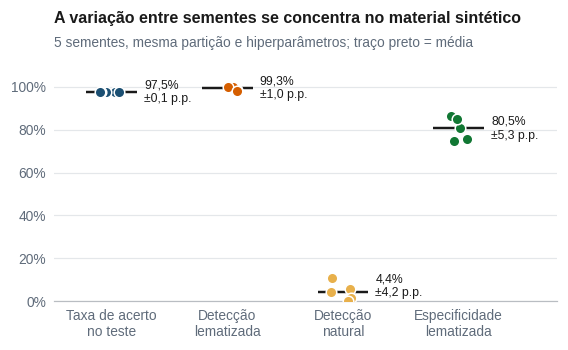

In [9]:
est = pd.read_csv(arquivo('estudo_sementes.csv'))
medidas = [('acuracia_teste', 'Taxa de acerto\nno teste', AZUL),
           ('deteccao_lematizada', 'Detecção\nlematizada', LARANJA),
           ('deteccao_natural', 'Detecção\nnatural', AMBAR),
           ('especificidade_lematizada', 'Especificidade\nlematizada', VERDE)]
medidas = [m for m in medidas if m[0] in est.columns]

fig, ax = plt.subplots(figsize=(LARGURA, 7.2 * CM))
rng = np.random.default_rng(0)
for k, (col, rotulo, cor) in enumerate(medidas):
    v = est[col].to_numpy()
    ax.scatter(k + rng.uniform(-0.10, 0.10, len(v)), v, s=48, color=cor,
               edgecolor='white', linewidth=1.0, zorder=3)
    ax.hlines(v.mean(), k - 0.22, k + 0.22, color=TEXTO, linewidth=1.6, zorder=2)
    texto = pct(v.mean())
    if len(v) > 1:
        texto += '\n±' + br('{:.1f}'.format(100 * v.std(ddof=1))) + ' p.p.'
    ax.annotate(texto, xy=(k + 0.28, max(v.mean(), 0.07)), ha='left', va='center',
                fontsize=T_PEQUENO, color=TEXTO)

ax.set_xticks(range(len(medidas)), [m[1] for m in medidas])
ax.set_xlim(-0.5, len(medidas) - 0.15)
escala_percentual(ax, folga_topo=0.12)
grade_y(ax)
amp = {c: est[c].max() - est[c].min() for c, _, _ in medidas}
sinteticas = max(v for c, v in amp.items() if c != 'acuracia_teste')
titulo(ax, ('A variação entre sementes se concentra no material sintético'
            if sinteticas > 3 * max(amp['acuracia_teste'], 0.001) else
            'Variação entre sementes'),
       '{} sementes, mesma partição e hiperparâmetros; traço preto = média'.format(len(est)))
salvar(fig, 'fig_sementes')
plt.show()
